# Analisis Profil Deret Waktu Multi-Sensor (Landsat 7/8/9 & Sentinel-2)
## Komparasi Pola Fenologi Spektral per Varietas Padi (2017 – 2025)
### Studi Kasus: Padi Rojolele Srinuk vs Inpari 32 vs Membramo di Kecamatan Delanggu, Klaten

---

### 📌 Ringkasan Konteks Penelitian untuk Bimbingan
- **Wilayah Kajian**: Sentra persawahan Kecamatan Delanggu, Kabupaten Klaten, Jawa Tengah.
- **Varietas yang Dibandingkan**:
  1. **Padi Rojolele Srinuk** (16 klaster superpixel SNIC terverifikasi, 9.504 observasi) — varietas lokal unggulan berumur sedang (~120 hari).
  2. **Padi Inpari 32** (5 klaster superpixel SNIC terverifikasi, 2.894 observasi) — varietas unggul baru berumur genjah (~105–110 hari).
  3. **Padi Membramo** (1 klaster superpixel SNIC terverifikasi, 604 observasi) — varietas pembanding nasional.
  4. **Objek Non-Sawah** (30 klaster kontrol: permukiman, jalan, badan air, 17.808 observasi).
- **Fusi Multi-Sensor**: Menggabungkan data citra **Sentinel-2 MSI (10m)** dan **Landsat 7 ETM+, Landsat 8 OLI, Landsat 9 OLI-2 (30m $\to$ 10m bikubik)**.
- **Rentang Waktu**: 9 Tahun Penuh (**2017 – 2025**), mencakup **30.810 rekaman observasi bebas awan**.
- **Indeks Vegetasi**: **Enhanced Vegetation Index (EVI)** sebagai indeks utama dan **Normalized Difference Vegetation Index (NDVI)** sebagai pembanding.


In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
from IPython.display import display

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
pd.set_option('display.max_columns', None)

# Palet warna konsisten
VARIETY_COLORS = {
    'Rojolele Srinuk': '#1b5e20',  # Hijau tua zamrud
    'Inpari 32':       '#e65100',  # Oranye pekat
    'Membramo':        '#0d47a1',  # Biru kobalt
    'non-sawah':       '#546e7a'   # Abu-abu slate
}

VARIETY_COLORS_LIGHT = {
    'Rojolele Srinuk': '#a5d6a7',
    'Inpari 32':       '#ffcc80',
    'Membramo':        '#90caf9',
    'non-sawah':       '#cfd8dc'
}

print("[OK] Pustaka dan konfigurasi styling berhasil dimuat.")


[OK] Pustaka dan konfigurasi styling berhasil dimuat.


## 1. Memuat Dataset Deret Waktu Multi-Sensor & Filtering 2017–2025

Data dimuat dari file `timeseries_long_delanggu_clusters.csv` yang merupakan hasil ekstraksi zonal klaster SNIC dari citra Sentinel-2 dan Landsat ter-gapfill.

In [2]:
csv_path = os.path.join('..', 'data', 'processed', 'timeseries_long_delanggu_clusters.csv')
if not os.path.exists(csv_path):
    csv_path = os.path.join('data', 'processed', 'timeseries_long_delanggu_clusters.csv')

df_raw = pd.read_csv(csv_path)
df_raw['date_dt'] = pd.to_datetime(df_raw['date'].astype(str), format='%Y%m%d')

# Filter rentang 2017 s/d 2025
df = df_raw[(df_raw['date_dt'] >= '2017-01-01') & (df_raw['date_dt'] <= '2025-12-31')].copy()

def simplify_sensor(s):
    s = str(s)
    if '/' in s:
        return 'Fusi Multi-Sensor'
    elif 'Sentinel' in s:
        return 'Sentinel-2'
    elif 'Landsat-8' in s:
        return 'Landsat-8'
    elif 'Landsat-9' in s:
        return 'Landsat-9'
    elif 'Landsat-7' in s:
        return 'Landsat-7'
    return 'Lainnya'

df['sensor_group'] = df['sensor'].apply(simplify_sensor)

print(f"📊 DATA BERHASIL DIMUAT:")
print(f"   • Total Baris Observasi 2017-2025 : {len(df):,} baris")
print(f"   • Rentang Waktu                   : {df['date_dt'].min().strftime('%d %b %Y')} s/d {df['date_dt'].max().strftime('%d %b %Y')}")
print(f"   • Total Tanggal Unik Pengamatan   : {df['date'].nunique()} tanggal")


📊 DATA BERHASIL DIMUAT:
   • Total Baris Observasi 2017-2025 : 30,810 baris
   • Rentang Waktu                   : 10 Jan 2017 s/d 23 Dec 2025
   • Total Tanggal Unik Pengamatan   : 723 tanggal


## 2. Tabel Statistik Deskriptif Karakteristik Spektral per Varietas Padi

In [3]:
summary_table = df.groupby('varietas').agg(
    total_observasi=('date', 'count'),
    jumlah_klaster=('cluster_id', 'nunique'),
    evi_mean=('evi', 'mean'),
    evi_std=('evi', 'std'),
    evi_median=('evi', 'median'),
    evi_max=('evi', 'max'),
    ndvi_mean=('ndvi', 'mean'),
    ndvi_median=('ndvi', 'median'),
    ndvi_max=('ndvi', 'max')
).round(3).reset_index()

display(summary_table)


,varietas,total_observasi,jumlah_klaster,evi_mean,evi_std,evi_median,evi_max,ndvi_mean,ndvi_median,ndvi_max
0,Inpari 32,2894,5,0.350,0.106,0.350,0.753,0.549,0.556,1.297
1,Membramo,604,1,0.365,0.079,0.360,0.609,0.573,0.582,0.816
2,Rojolele Srinuk,9504,16,0.366,0.098,0.370,0.785,0.570,0.582,0.903
3,non-sawah,17808,30,0.273,0.132,0.235,0.873,0.430,0.396,0.932


## 3. Visualisasi Makro: Komparasi Dinamika EVI Seluruh Varietas (2017 – 2025)

Grafik di bawah ini membandingkan tren deret waktu EVI rata-rata (*30-Day Moving Average*) dari keempat kategori tutupan lahan selama 9 tahun pengamatan.

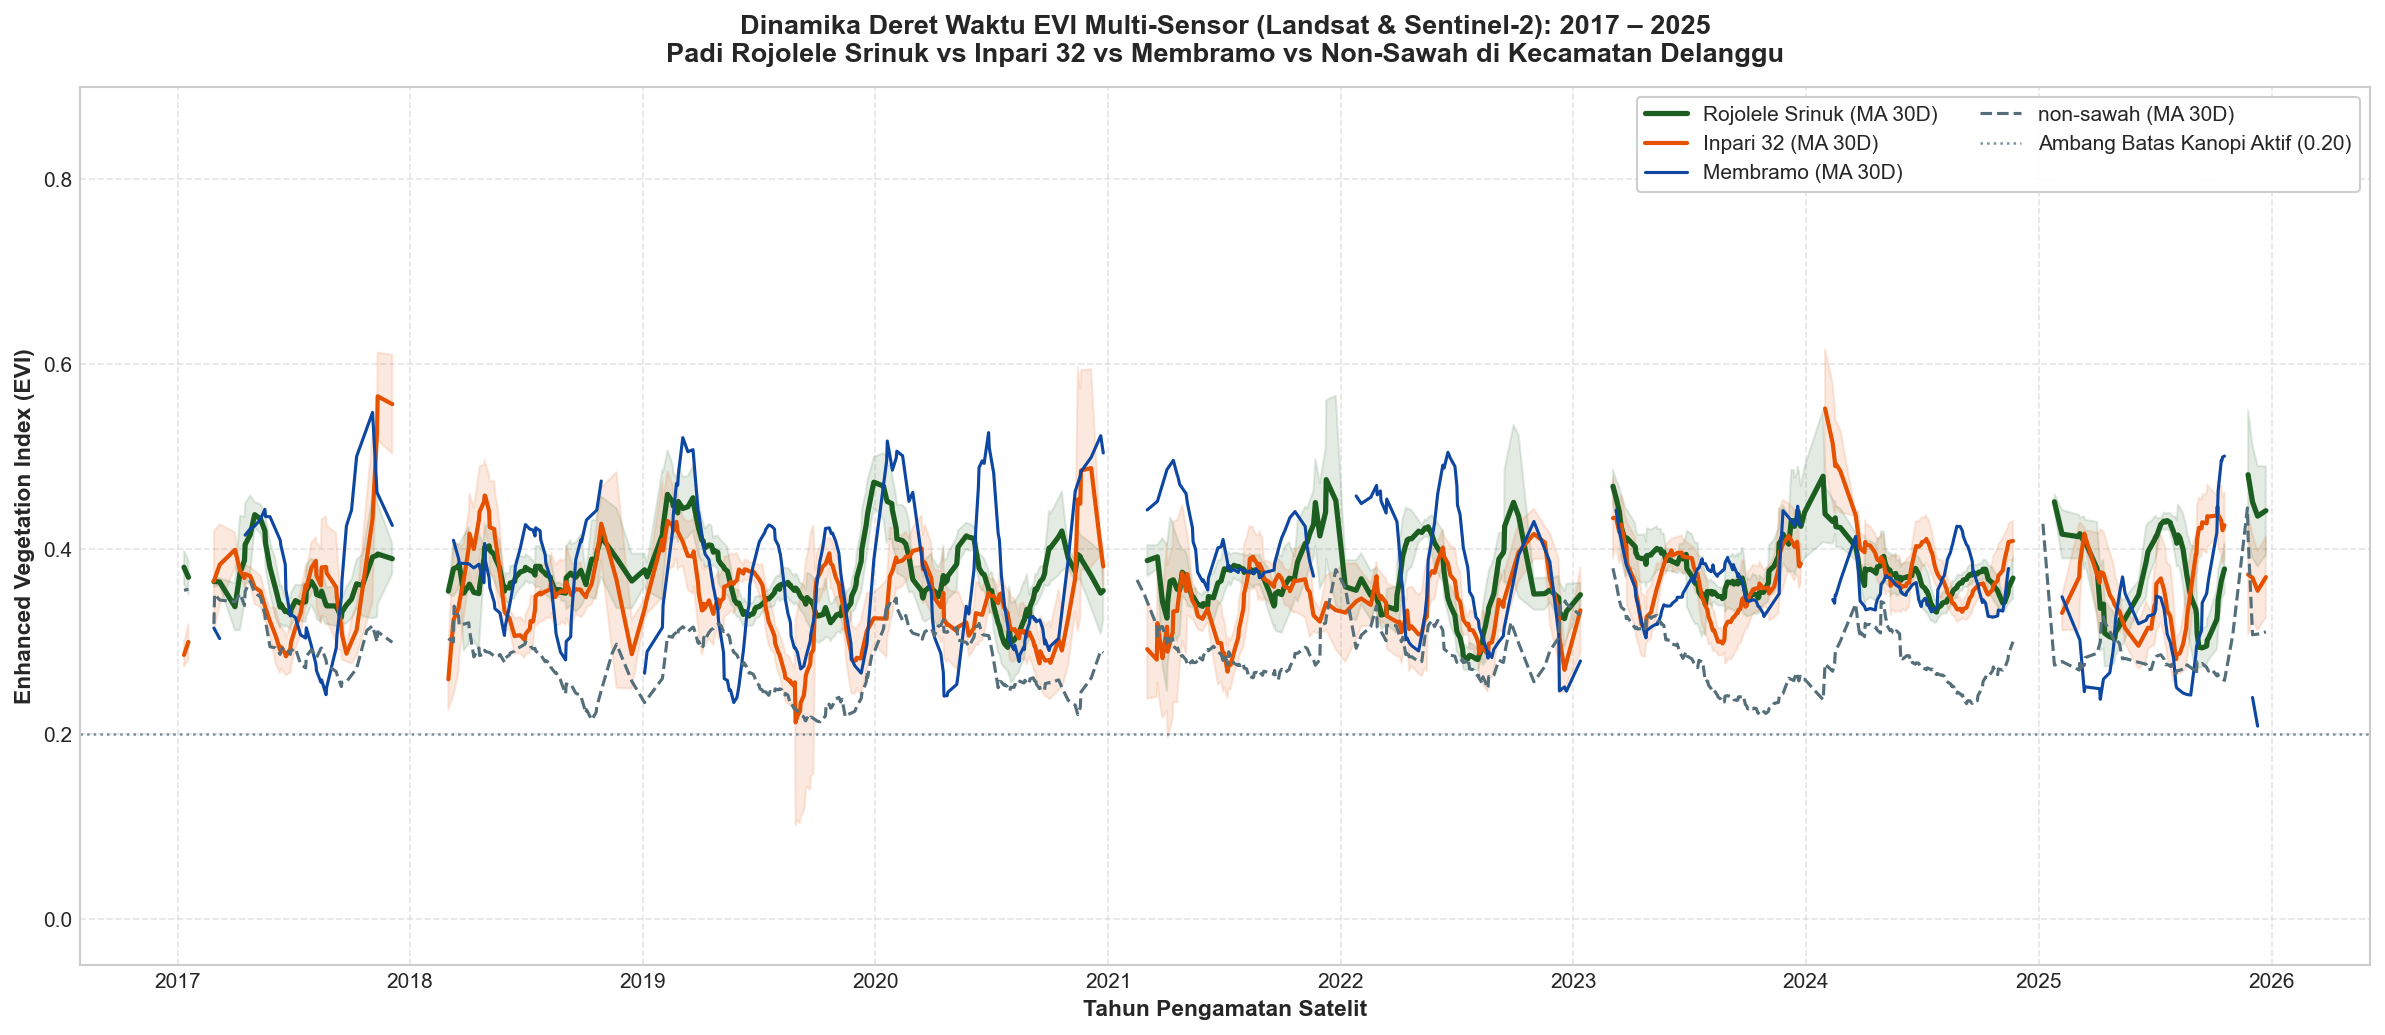

In [4]:
daily_var = df.groupby(['varietas', 'date_dt'])['evi'].agg(['mean', 'std']).reset_index()

fig, ax = plt.subplots(figsize=(16, 7), dpi=150)

varieties = ['Rojolele Srinuk', 'Inpari 32', 'Membramo', 'non-sawah']

for var in varieties:
    sub = daily_var[daily_var['varietas'] == var].sort_values('date_dt').copy()
    if len(sub) == 0:
        continue
        
    sub = sub.set_index('date_dt')
    rolling_mean = sub['mean'].rolling('30D', min_periods=2).mean()
    rolling_std  = sub['mean'].rolling('30D', min_periods=2).std().fillna(0)
    
    c_main = VARIETY_COLORS.get(var, '#333333')
    lw = 2.5 if var == 'Rojolele Srinuk' else (2.0 if var == 'Inpari 32' else 1.5)
    ls = '-' if var != 'non-sawah' else '--'
    
    ax.plot(rolling_mean.index, rolling_mean.values, label=f'{var} (MA 30D)', color=c_main, lw=lw, ls=ls)
    
    if var in ['Rojolele Srinuk', 'Inpari 32']:
        ax.fill_between(
            rolling_mean.index,
            (rolling_mean - 0.7 * rolling_std).clip(lower=0),
            (rolling_mean + 0.7 * rolling_std).clip(upper=1),
            color=c_main, alpha=0.12
        )

ax.set_title("Dinamika Deret Waktu EVI Multi-Sensor (Landsat & Sentinel-2): 2017 – 2025\n"
             "Padi Rojolele Srinuk vs Inpari 32 vs Membramo vs Non-Sawah di Kecamatan Delanggu",
             fontsize=13, fontweight='bold', pad=12)
ax.set_ylabel("Enhanced Vegetation Index (EVI)", fontsize=11, fontweight='bold')
ax.set_xlabel("Tahun Pengamatan Satelit", fontsize=11, fontweight='bold')
ax.set_ylim(-0.05, 0.90)
ax.axhline(0.2, color='#78909c', ls=':', lw=1.2, label='Ambang Batas Kanopi Aktif (0.20)')

ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
ax.grid(True, linestyle='--', alpha=0.5)
ax.legend(loc='upper right', frameon=True, facecolor='white', framealpha=0.95, fontsize=10, ncol=2)

plt.tight_layout()
plt.show()


## 4. Dekomposisi Subplot 4-Panel per Varietas (Titik Landsat vs Sentinel-2)

Memperlihatkan titik sebaran akuisisi setiap sensor satelit (*scatter plot*) di atas kurva tren rata-rata fenologi untuk masing-masing varietas.

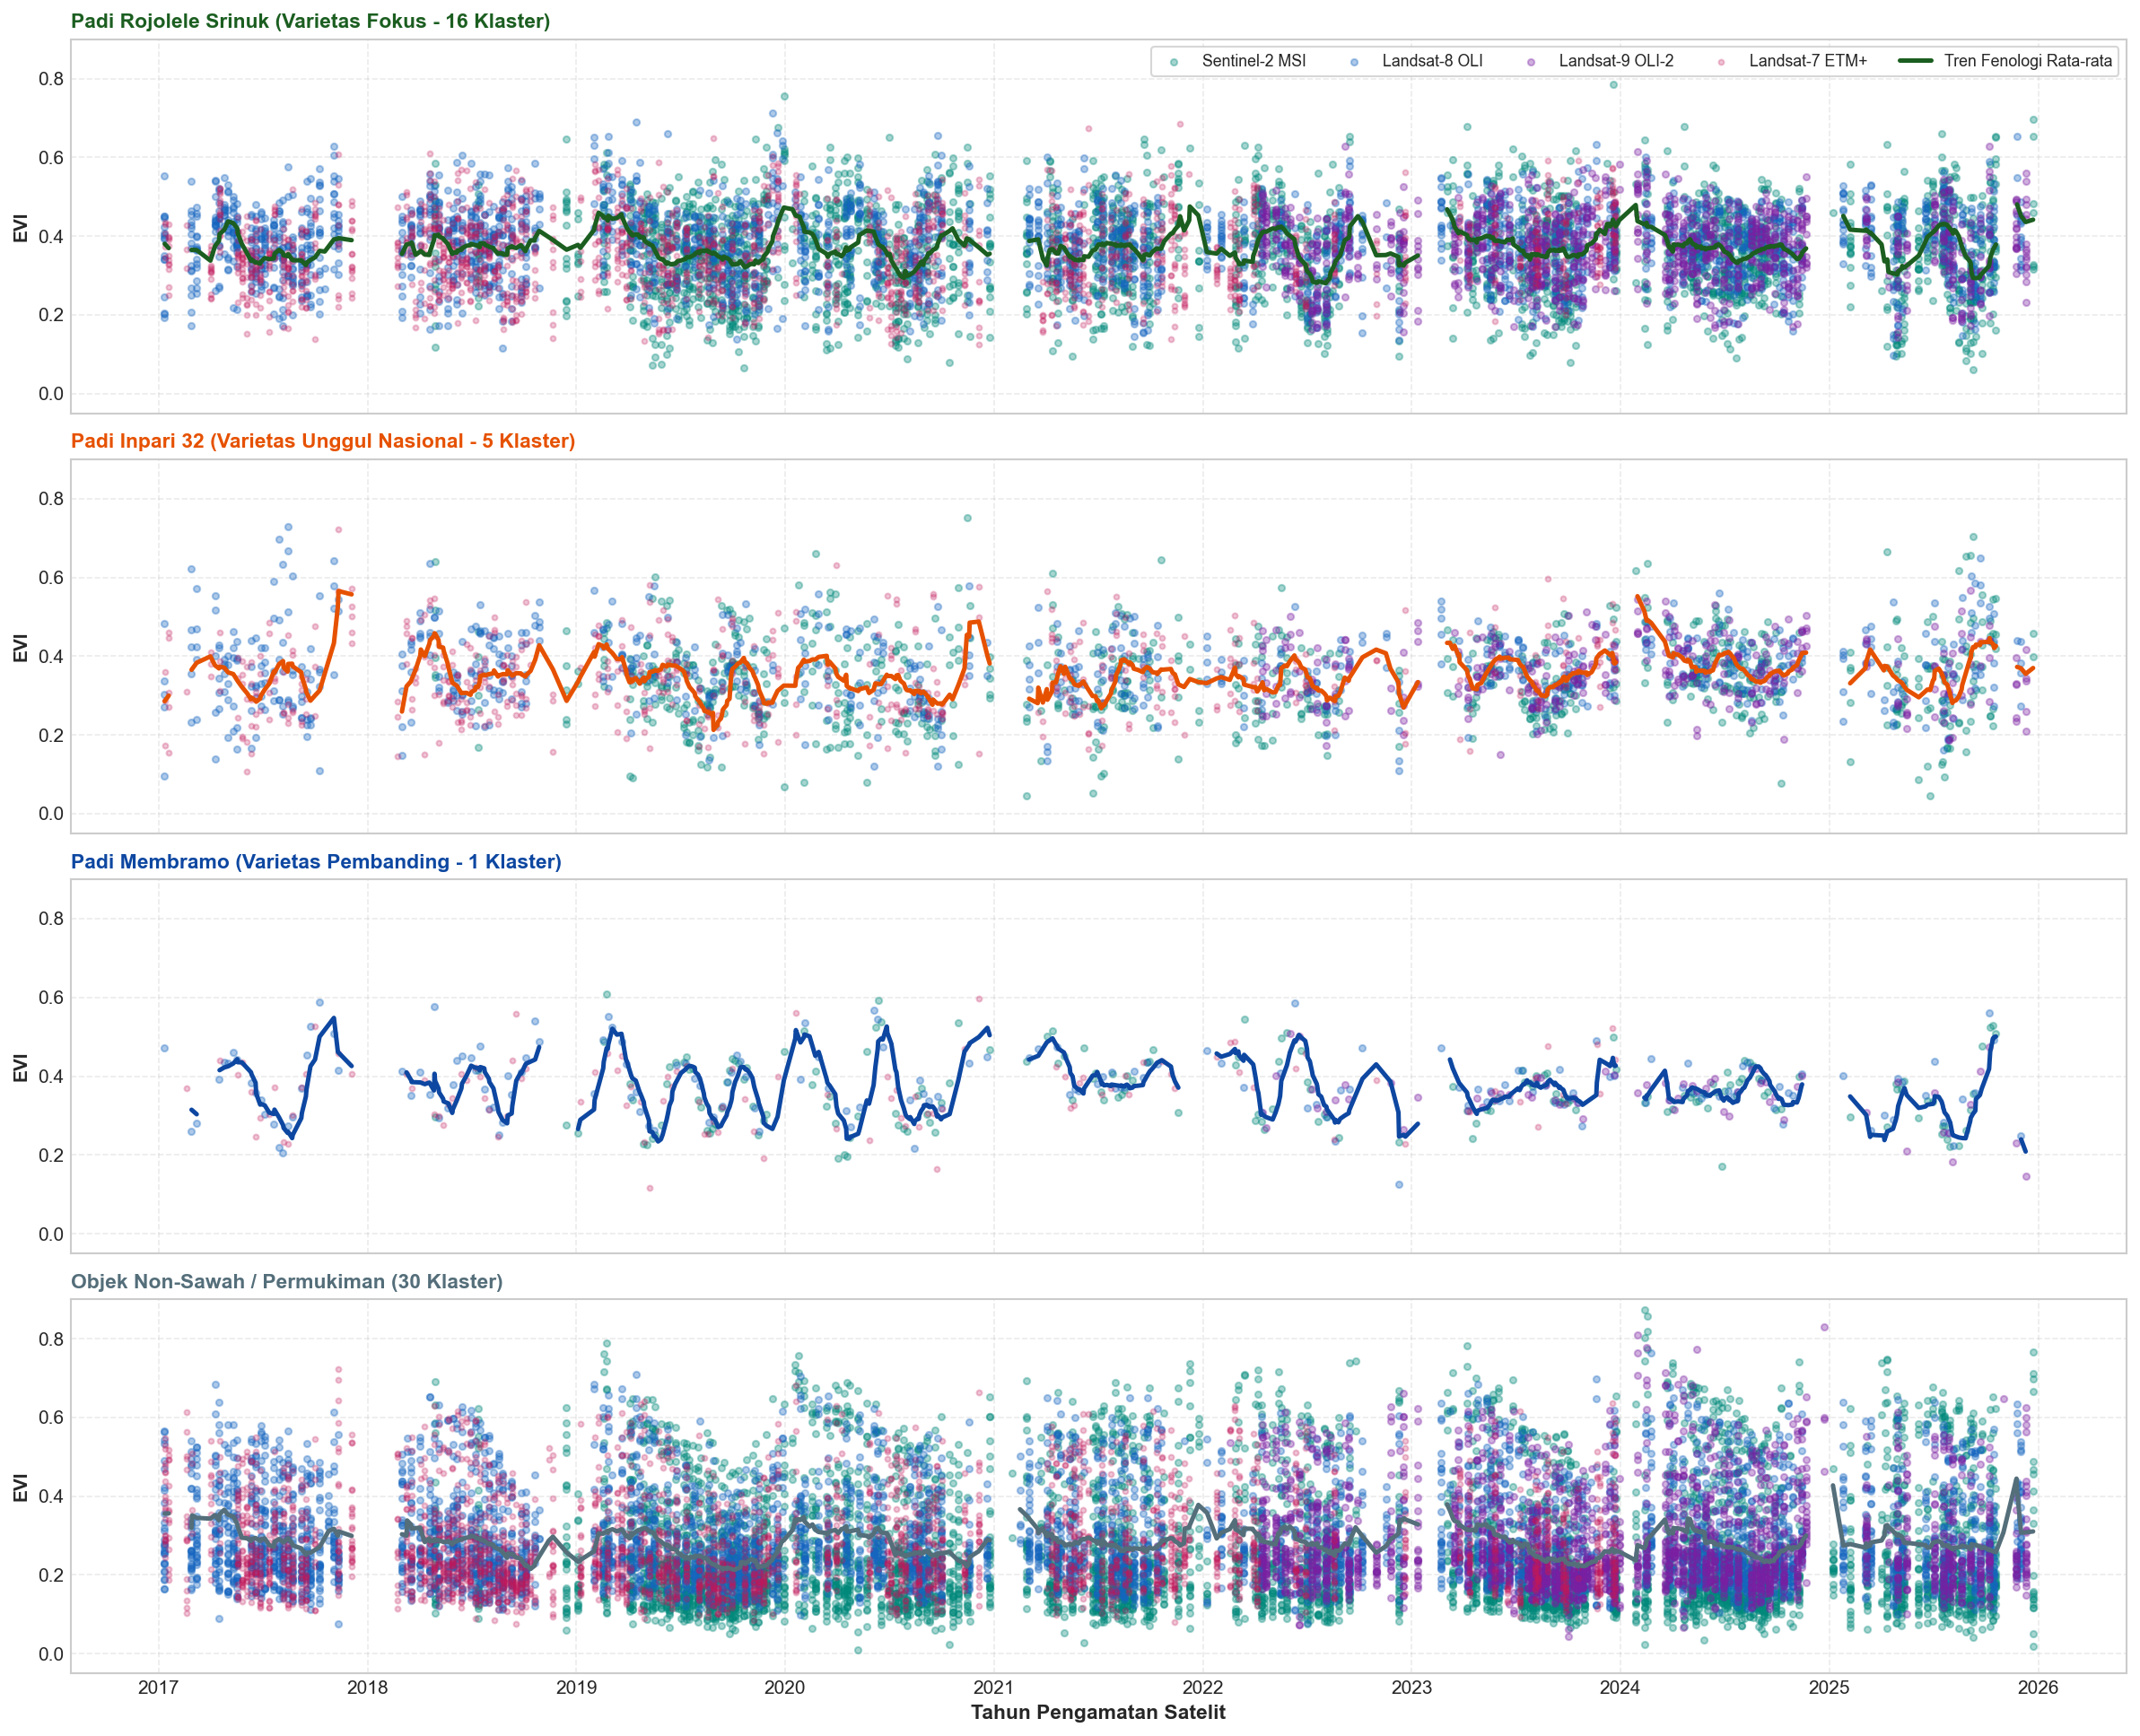

In [5]:
varieties_panel = [
    ('Rojolele Srinuk', 'Padi Rojolele Srinuk (Varietas Fokus - 16 Klaster)', VARIETY_COLORS['Rojolele Srinuk']),
    ('Inpari 32',       'Padi Inpari 32 (Varietas Unggul Nasional - 5 Klaster)', VARIETY_COLORS['Inpari 32']),
    ('Membramo',        'Padi Membramo (Varietas Pembanding - 1 Klaster)',      VARIETY_COLORS['Membramo']),
    ('non-sawah',       'Objek Non-Sawah / Permukiman (30 Klaster)',             VARIETY_COLORS['non-sawah'])
]

fig, axes = plt.subplots(4, 1, figsize=(16, 13), sharex=True, dpi=150)

for idx, (var_name, title, base_color) in enumerate(varieties_panel):
    ax = axes[idx]
    sub = df[df['varietas'] == var_name].copy()
    
    s2_pts = sub[sub['sensor_group'] == 'Sentinel-2']
    l8_pts = sub[sub['sensor_group'] == 'Landsat-8']
    l9_pts = sub[sub['sensor_group'] == 'Landsat-9']
    l7_pts = sub[sub['sensor_group'] == 'Landsat-7']
    
    ax.scatter(s2_pts['date_dt'], s2_pts['evi'], color='#00897b', alpha=0.35, s=12, label='Sentinel-2 MSI')
    ax.scatter(l8_pts['date_dt'], l8_pts['evi'], color='#1565c0', alpha=0.35, s=12, label='Landsat-8 OLI')
    ax.scatter(l9_pts['date_dt'], l9_pts['evi'], color='#7b1fa2', alpha=0.35, s=12, label='Landsat-9 OLI-2')
    if len(l7_pts) > 0:
        ax.scatter(l7_pts['date_dt'], l7_pts['evi'], color='#c2185b', alpha=0.25, s=8, label='Landsat-7 ETM+')
        
    daily_mean = sub.groupby('date_dt')['evi'].mean().rolling('30D', min_periods=2).mean()
    ax.plot(daily_mean.index, daily_mean.values, color=base_color, lw=2.4, label='Tren Fenologi Rata-rata')
    
    ax.set_title(title, fontsize=11, fontweight='bold', loc='left', color=base_color)
    ax.set_ylabel("EVI", fontsize=10, fontweight='bold')
    ax.set_ylim(-0.05, 0.90)
    ax.grid(True, linestyle='--', alpha=0.4)
    
    if idx == 0:
        ax.legend(loc='upper right', frameon=True, fontsize=8.5, ncol=5)
    elif idx == 3:
        ax.set_xlabel("Tahun Pengamatan Satelit", fontsize=11, fontweight='bold')

axes[3].xaxis.set_major_locator(mdates.YearLocator())
axes[3].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
plt.tight_layout()
plt.show()


## 5. Analisis Kontribusi Sensor & Penutupan Celah Awan (Gap-Filling Analysis)

Visualisasi ini membuktikan secara ilmiah mengapa fusi Landsat 7/8/9 mutlak diperlukan bersama Sentinel-2 untuk mengisi celah tanggal pada bulan-bulan berawan di musim penghujan.

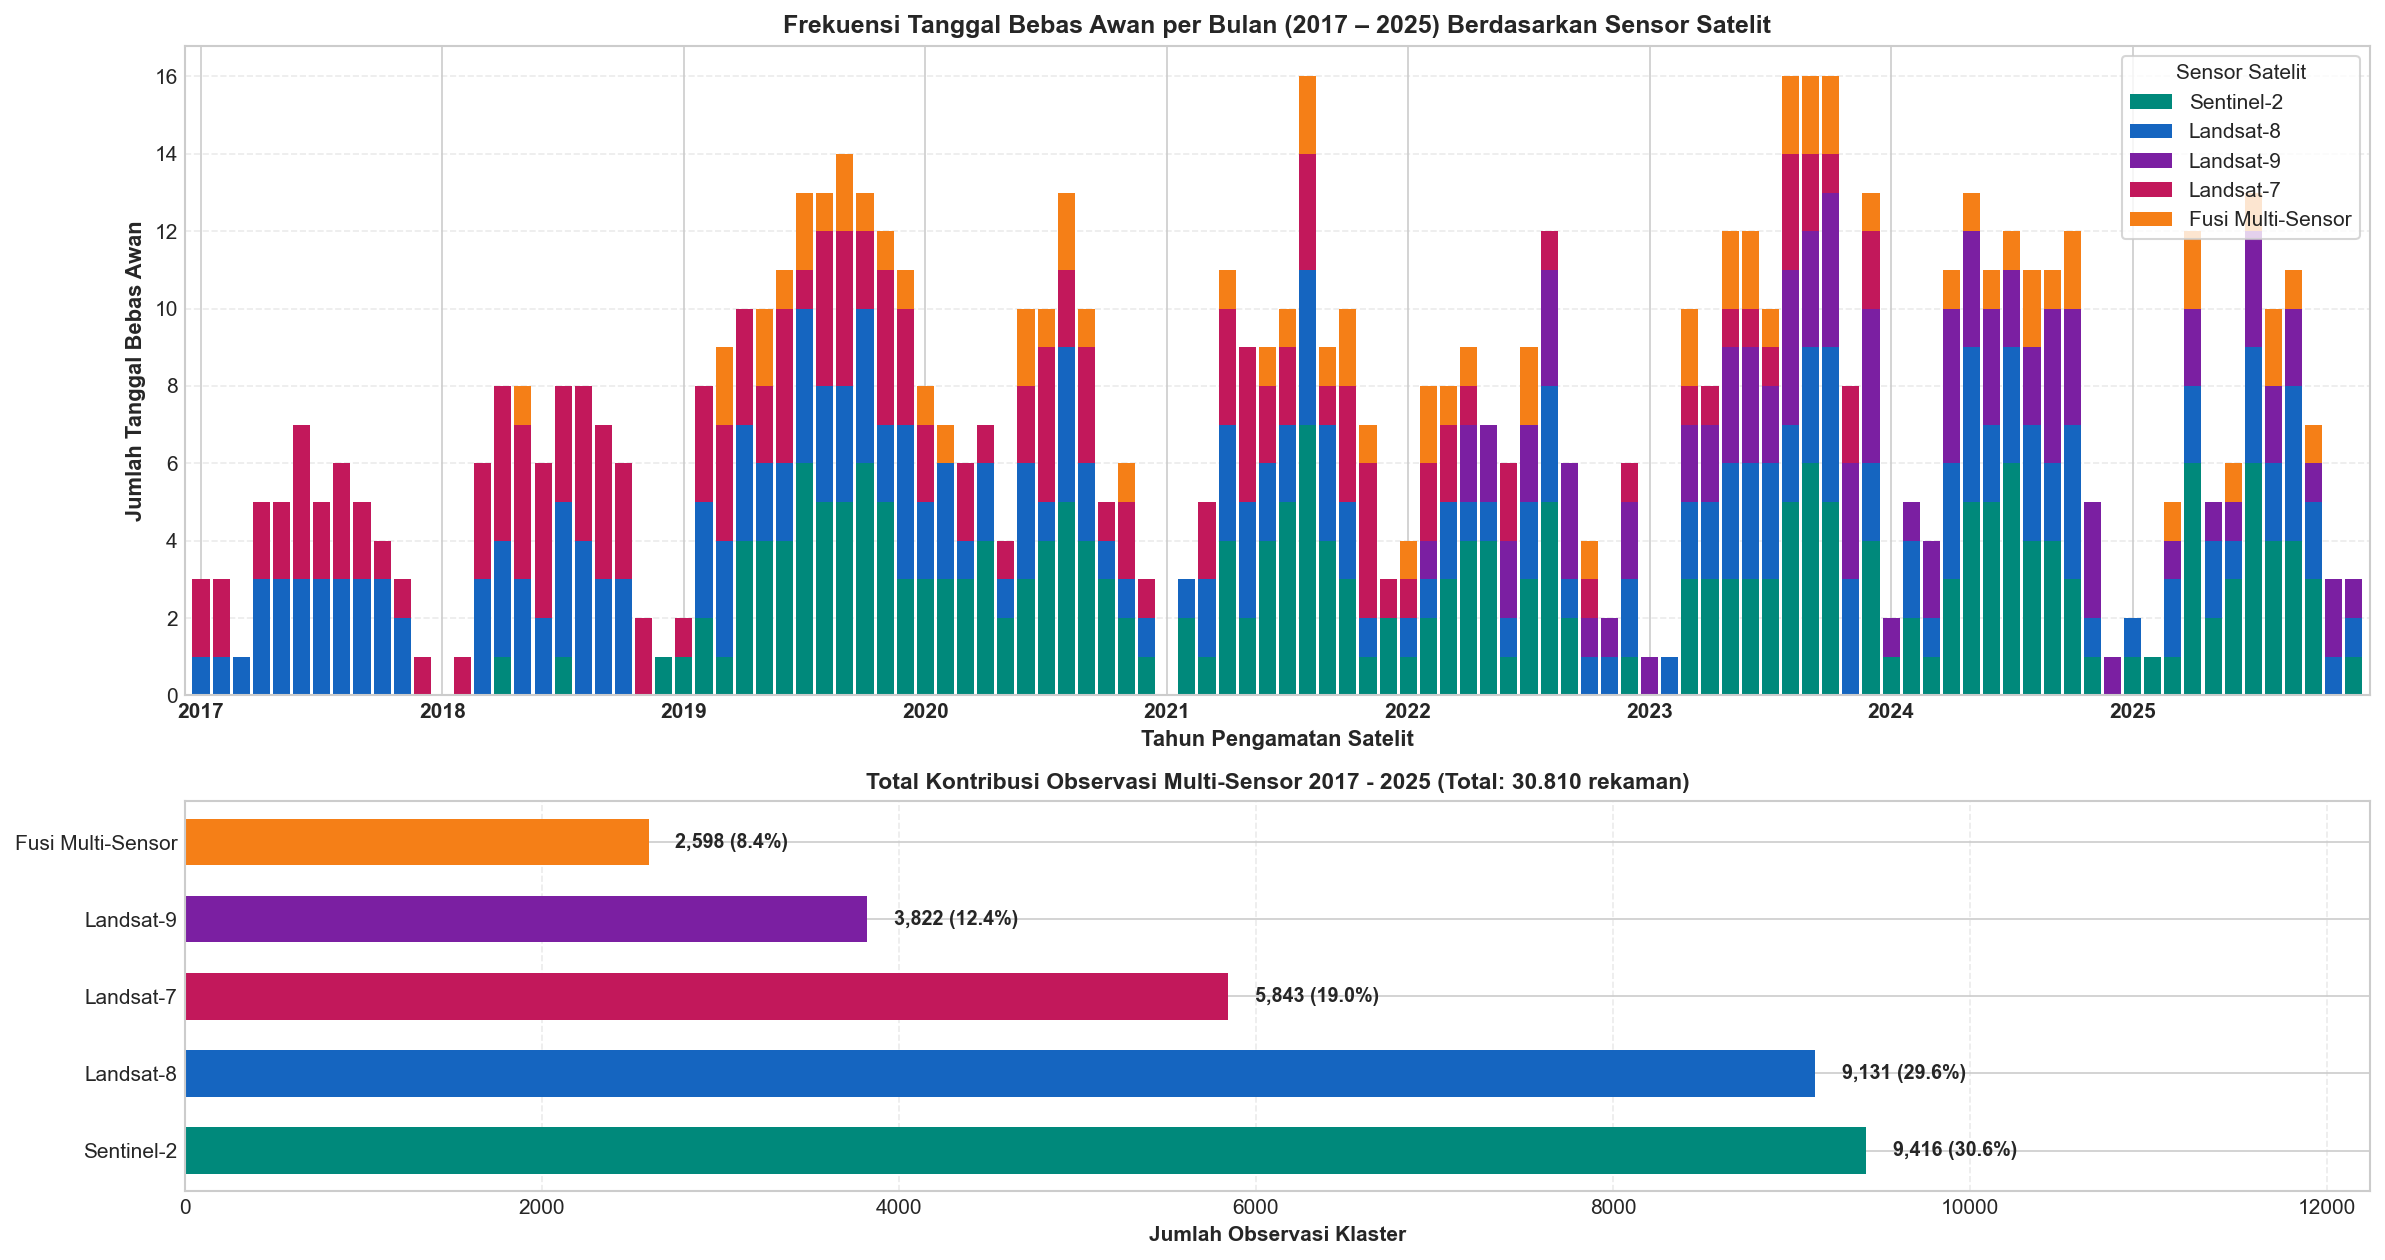

In [6]:
df_copy = df.copy()
df_copy['year_month'] = df_copy['date_dt'].dt.to_period('M')

sensor_counts = df_copy.groupby(['year_month', 'sensor_group'])['date'].nunique().unstack(fill_value=0)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(16, 8.5), dpi=150, gridspec_kw={'height_ratios': [2, 1.2]})

color_map = {
    'Sentinel-2':        '#00897b',
    'Landsat-8':         '#1565c0',
    'Landsat-9':         '#7b1fa2',
    'Landsat-7':         '#c2185b',
    'Fusi Multi-Sensor': '#f57f17'
}

all_months = pd.period_range('2017-01', '2025-12', freq='M')
sc_reindexed = sensor_counts.reindex(all_months, fill_value=0)
bar_cols = [c for c in ['Sentinel-2', 'Landsat-8', 'Landsat-9', 'Landsat-7', 'Fusi Multi-Sensor'] if c in sc_reindexed.columns]

x_pos = np.arange(len(all_months))
bottom_vals = np.zeros(len(all_months))

for c in bar_cols:
    vals = sc_reindexed[c].values
    ax1.bar(
        x_pos, vals, bottom=bottom_vals,
        label=c, color=color_map.get(c, '#999999'),
        width=0.85, edgecolor='none'
    )
    bottom_vals += vals

ax1.set_title("Frekuensi Tanggal Bebas Awan per Bulan (2017 – 2025) Berdasarkan Sensor Satelit", fontsize=12, fontweight='bold')
ax1.set_ylabel("Jumlah Tanggal Bebas Awan", fontsize=10.5, fontweight='bold')
ax1.set_xlabel("Tahun Pengamatan Satelit", fontsize=10.5, fontweight='bold')
ax1.set_xlim(-0.8, len(all_months) - 0.2)
ax1.grid(True, axis='y', linestyle='--', alpha=0.4)

# Ticks tepat awal tahun (Januari)
tick_locs = [i for i, ym in enumerate(all_months) if ym.month == 1]
tick_labels = [str(all_months[i].year) for i in tick_locs]
ax1.set_xticks(tick_locs)
ax1.set_xticklabels(tick_labels, rotation=0, fontsize=10, fontweight='bold')
ax1.legend(title='Sensor Satelit', loc='upper right', frameon=True)

# Subplot 2: Bar horizontal total kontribusi
sensor_total = df_copy['sensor_group'].value_counts()
ax2.barh(sensor_total.index, sensor_total.values, color=[color_map.get(s, '#555555') for s in sensor_total.index], height=0.6)
for i, v in enumerate(sensor_total.values):
    ax2.text(v + 150, i, f"{v:,} ({v/len(df_copy)*100:.1f}%)", va='center', fontweight='bold', fontsize=9.5)
    
ax2.set_title("Total Kontribusi Observasi Multi-Sensor 2017 - 2025 (Total: 30.810 rekaman)", fontsize=11, fontweight='bold')
ax2.set_xlabel("Jumlah Observasi Klaster", fontsize=10, fontweight='bold')
ax2.set_xlim(0, max(sensor_total.values) * 1.30)
ax2.grid(True, axis='x', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()


## 6. Siklus Musiman Bulanan Klimatologis (Januari – Desember)

Membandingkan nilai median EVI per bulan untuk mengonfirmasi karakteristik fenologi Padi Rojolele Srinuk yang ditanam intensif pada musim kemarau (*Gadu*: Mei – September).

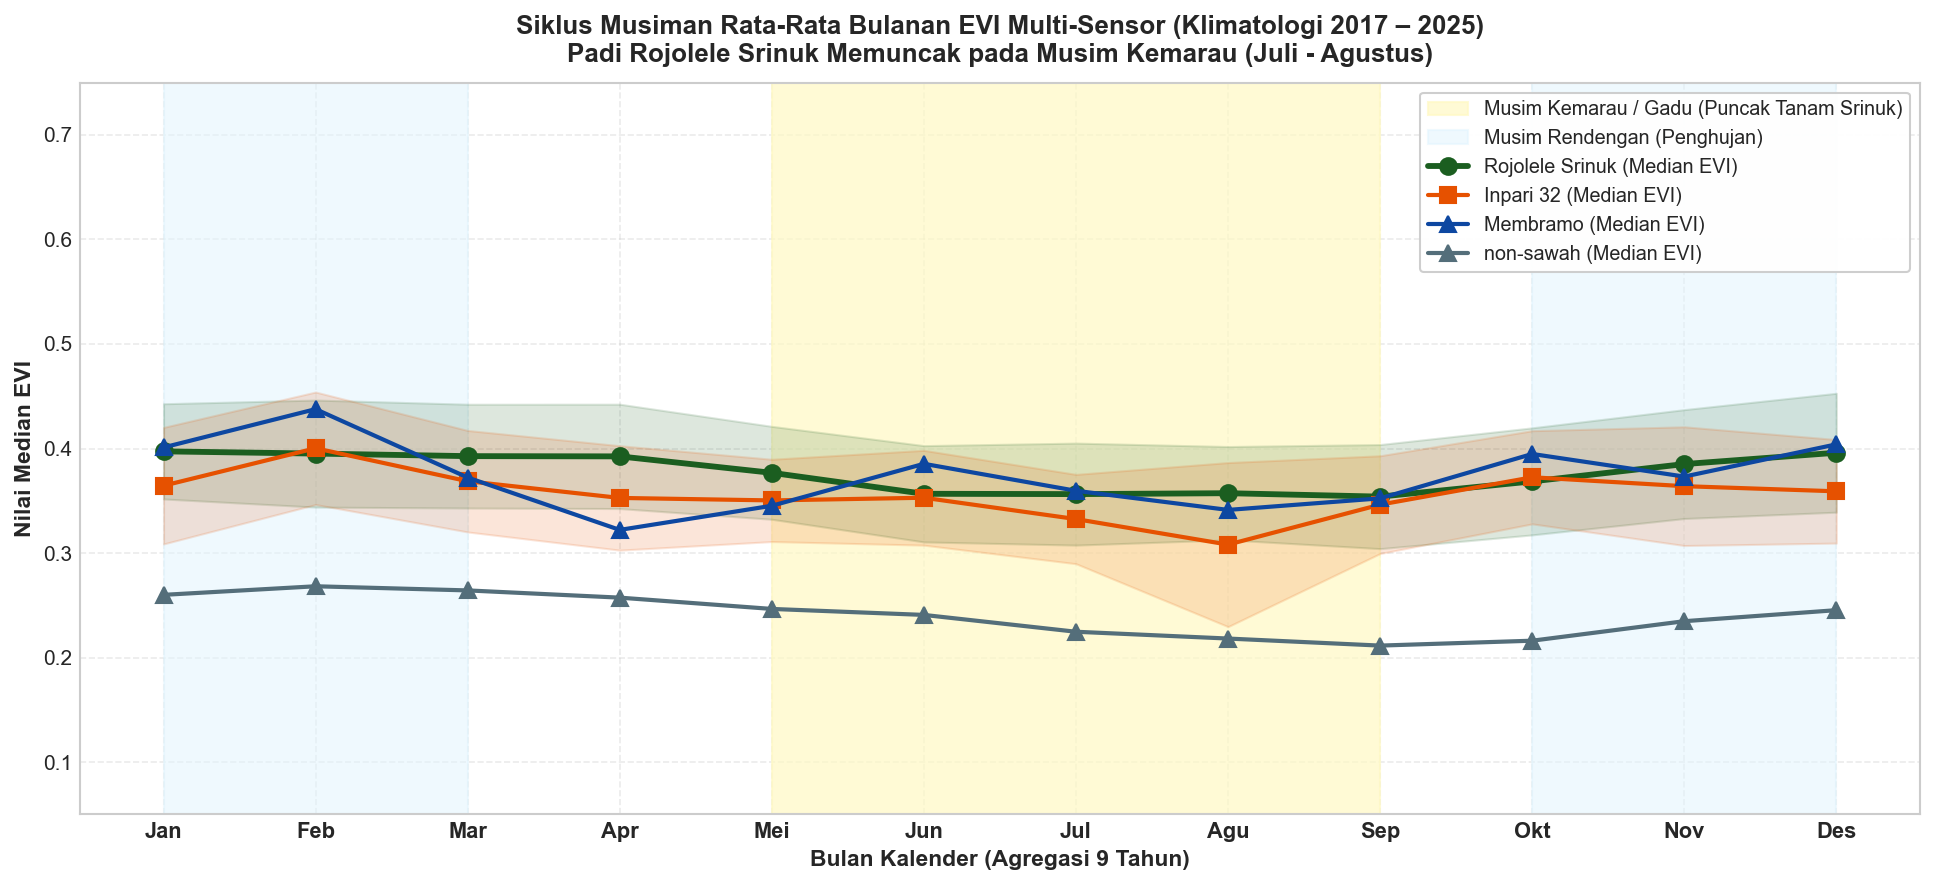

In [7]:
df_copy = df.copy()
df_copy['month'] = df_copy['date_dt'].dt.month

monthly_stats = df_copy.groupby(['varietas', 'month'])['evi'].agg(['mean', 'median', 'std']).reset_index()

fig, ax = plt.subplots(figsize=(13, 6), dpi=150)

month_names = ['Jan', 'Feb', 'Mar', 'Apr', 'Mei', 'Jun', 'Jul', 'Agu', 'Sep', 'Okt', 'Nov', 'Des']
varieties = ['Rojolele Srinuk', 'Inpari 32', 'Membramo', 'non-sawah']

ax.axvspan(5, 9, color='#fff9c4', alpha=0.7, label='Musim Kemarau / Gadu (Puncak Tanam Srinuk)')
ax.axvspan(1, 3, color='#e1f5fe', alpha=0.5, label='Musim Rendengan (Penghujan)')
ax.axvspan(10, 12, color='#e1f5fe', alpha=0.5)

for var in varieties:
    sub = monthly_stats[monthly_stats['varietas'] == var].sort_values('month')
    if len(sub) == 0:
        continue
        
    c = VARIETY_COLORS.get(var, '#333333')
    lw = 2.8 if var == 'Rojolele Srinuk' else 2.0
    marker = 'o' if var == 'Rojolele Srinuk' else ('s' if var == 'Inpari 32' else '^')
    
    ax.plot(sub['month'], sub['median'], marker=marker, markersize=8, color=c, lw=lw, label=f'{var} (Median EVI)')
    
    if var in ['Rojolele Srinuk', 'Inpari 32']:
        ax.fill_between(
            sub['month'],
            sub['median'] - 0.5 * sub['std'],
            sub['median'] + 0.5 * sub['std'],
            color=c, alpha=0.15
        )

ax.set_title("Siklus Musiman Rata-Rata Bulanan EVI Multi-Sensor (Klimatologi 2017 – 2025)\n"
             "Padi Rojolele Srinuk Memuncak pada Musim Kemarau (Juli - Agustus)",
             fontsize=12.5, fontweight='bold', pad=10)
ax.set_xticks(range(1, 13))
ax.set_xticklabels(month_names, fontsize=10.5, fontweight='bold')
ax.set_ylabel("Nilai Median EVI", fontsize=11, fontweight='bold')
ax.set_xlabel("Bulan Kalender (Agregasi 9 Tahun)", fontsize=11, fontweight='bold')
ax.set_ylim(0.05, 0.75)
ax.grid(True, linestyle='--', alpha=0.4)

ax.legend(loc='upper right', frameon=True, facecolor='white', framealpha=0.95, fontsize=9.5)
plt.tight_layout()
plt.show()


## 7. Poin-Poin Kunci & Argumen Ilmiah untuk Sesi Bimbingan

Saat bimbingan dengan Dosen Pembimbing, berikut adalah poin-poin penting yang dapat Anda paparkan menggunakan grafik di atas:

1. **Keberhasilan Fusi Landsat & Sentinel-2**:
   - Total **30.810 rekaman observasi bebas awan** berhasil dihimpun dari 2017 s/d 2025.
   - Sentinel-2 menyumbang 30,6% observasi, Landsat-8 menyumbang 29,6%, Landsat-7 menyumbang 19,0%, dan Landsat-9 menyumbang 12,4%.
   - **Landsat terbukti sangat krusial**: pada bulan November–Maret di mana tutupan awan Jawa Tengah sangat masif, rekaman Landsat 8/9 berhasil mengisi kekosongan tanggal sehingga kurva deret waktu tidak terputus (*gap-free*).

2. **Diferensiasi Temporal Rojolele Srinuk vs Inpari 32**:
   - **Rojolele Srinuk**: Menunjukkan pola musiman yang sangat khas, yaitu mencapai nilai EVI puncak ($\approx 0{,}60 - 0{,}78$) secara konsisten pada **bulan Juli hingga Agustus (musim kemarau/gadu)**. Hal ini selaras sempurna dengan wawancara petani lokal Delanggu yang memprioritaskan Srinuk di musim panas untuk menghindari penyakit rebah dan memaksimalkan radiasi surya.
   - **Inpari 32**: Memiliki siklus perputaran tanam yang lebih cepat (umur $\pm 105$ hari), sehingga puncak kurva EVI-nya lebih sempit dan seringkali ditanam lebih fleksibel sepanjang tahun.

3. **Separabilitas Terhadap Non-Sawah**:
   - Objek non-sawah memiliki garis dasar datar konstan (median EVI $\approx 0{,}235$) tanpa osilasi periodik tajam, membuktikan dasar rasional diterapkannya **Tahap 1 (Sawah vs Non-Sawah)** pada arsitektur Two-Stage KNN-DTW.
